# COMP8410 A1 - Week 5 (TRELLIS.2 vs Hunyuan3D 2.1, single image to 3D) - Colab
**Two sessions.** Part A on a cheap **T4** runtime builds both environments and packs them to Drive. Part B on an **A100** unpacks them and does all generation and scoring. If Part A is skipped, Cell B1 builds the environments on the A100 instead (works, costs more).
Before running: Hugging Face account with an access token (read), and accepted terms for the gated models the TRELLIS.2 pipeline loads (Cell B3 prints which ones). Photos: Drive `comp8410_a1/w5_data/setC/`.
Before saving: tick *Omit code cell output when saving*. **Disconnect the runtime when finished** (last cell).

## Part A (T4 runtime): shared setup, then build and pack the environments

In [2]:
%cd /content
from google.colab import drive
import os
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/comp8410_a1'
for d in ['results', 'outputs', 'logs', 'w5_data', 'w5_envs']:
    os.makedirs(f'{BASE}/{d}', exist_ok=True)
!rm -rf /content/a1 && git clone https://github.com/yash1998-MQ-AI/COMP8410-A1-48576158.git /content/a1
%cd "/content/a1/48576158 Evaluation"
!pip -q install -r requirements.txt
!pip -q install trimesh scipy tabulate rembg onnxruntime transformers lpips
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
Cloning into '/content/a1'...
remote: Enumerating objects: 306, done.
remote: Counting objects: 100% (306/306), done.
remote: Compressing objects: 100% (188/188), done.
remote: Total 306 (delta 113), reused 294 (delta 101), pack-reused 0 (from 0)
Receiving objects: 100% (306/306), 10.71 MiB | 23.99 MiB/s, done.
Resolving deltas: 100% (113/113), done.
/content/a1/48576158 Evaluation
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.68.1 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.68.1 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.68.1 which is incompatible.
name, memory.total [MiB]
NVIDI

In [3]:
# A1. micromamba + TRELLIS.2 environment (long: compiles CUDA extensions). Read the last lines of the output.
!bash pairs/w5_image_to_3d/install_envs.sh micromamba
!bash pairs/w5_image_to_3d/install_envs.sh trellis2 2>&1 | tee {BASE}/logs/w5_install_trellis2.log | tail -40

2.10.0

    micromamba run -n trellis2 mycommand


Transaction finished


Cloning into '/content/TRELLIS.2'...
Submodule 'o-voxel/third_party/eigen' (https://gitlab.com/libeigen/eigen.git) registered for path 'o-voxel/third_party/eigen'
Cloning into '/content/TRELLIS.2/o-voxel/third_party/eigen'...
Submodule path 'o-voxel/third_party/eigen': checked out '21e4582d1739107337a03460c81412981130373e'
  Created wheel for o_voxel: filename=o_voxel-0.0.1-cp310-cp310-linux_x86_64.whl size=240912 sha256=1b8b3f7a5aacaf0383c4336f38b2f9ecbbed62ee5a00b07bf85efef2185d95c9
  Stored in directory: /tmp/pip-ephem-wheel-cache-8lhfga08/wheels/6c/a8/0a/a6ee1550dd70f48e38845f0a8ba883b5bac9770e998f2700ca
Successfully built o_voxel
trellis2 env ok, torch 2.6.0+cu124


In [4]:
# A2. Hunyuan3D 2.1 environment. The last lines print the licence text: read it (territory and use limits) for the report.
!bash pairs/w5_image_to_3d/install_envs.sh hunyuan 2>&1 | tee {BASE}/logs/w5_install_hunyuan.log | tail -60


    micromamba run -n hunyuan mycommand


Transaction finished


Cloning into '/content/Hunyuan3D-2.1'...
Updating files: 100% (598/598), done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.6/104.6 MB 6.5 MB/s  0:00:16
ERROR: Ignored the following versions that require a different python version: 0.26.0 Requires-Python >=3.11; 0.26.0rc1 Requires-Python >=3.11; 0.26.0rc2 Requires-Python >=3.11; 0.27.0rc1 Requires-Python >=3.12; 0.42.0 Requires-Python >=3.11.0; 0.42.1 Requires-Python >=3.11.0; 1.16.0 Requires-Python >=3.11; 1.16.0rc1 Requires-Python >=3.11; 1.16.0rc2 Requires-Python >=3.11; 1.16.1 Requires-Python >=3.11; 1.16.2 Requires-Python >=3.11; 1.16.3 Requires-Python >=3.11; 1.17.0 Requires-Python >=3.11; 1.17.0rc1 Requires-Python >=3.11; 1.17.0rc2 Requires-Python >=3.11; 1.17.1 Requires-Python >=3.11; 1.18.0 Requires-Python >=3.12; 1.18.0rc1 Requires-Python >=3.12; 1.18.0rc2 Requires-Python >=3.12; 1.18.1 Requires-Python >=3.12; 1.6.2 Requires-Python >=3.7,<3.10; 1.6.3 Requi

In [2]:
import os
os.environ['MAMBA_ROOT_PREFIX'] = '/content/mamba'
os.environ['CUDA_HOME'] = '/content/mamba/envs/hunyuan'
os.environ['TORCH_CUDA_ARCH_LIST'] = '8.0'
os.environ['PATH'] = '/content/mamba/envs/hunyuan/bin:' + os.environ['PATH']
%cd /content/Hunyuan3D-2.1
MM = '/content/bin/micromamba run -n hunyuan'
!grep -viE '^\s*bpy' requirements.txt > /tmp/hy_requirements.txt
!{MM} pip install -r /tmp/hy_requirements.txt 2>&1 | tail -8
!{MM} pip install pybind11 setuptools wheel ninja 2>&1 | tail -1
!cd hy3dpaint/custom_rasterizer && {MM} pip install --no-build-isolation -e . 2>&1 | tail -8
!cd hy3dpaint/DifferentiableRenderer && {MM} bash compile_mesh_painter.sh 2>&1 | tail -5
!printf '"""Stub for bpy (no wheel on this platform)."""\n' > hy3dpaint/bpy.py
!cd hy3dpaint && {MM} python -c "import sys; sys.path[:0]=['.','../hy3dshape']; from textureGenPipeline import Hunyuan3DPaintPipeline; print('HUNYUAN IMPORTS OK')" 2>&1 | tail -6
!cd /content/TRELLIS.2 && /content/bin/micromamba run -n trellis2 python -c "import flash_attn, nvdiffrast.torch, cumesh, flex_gemm; print('TRELLIS EXTENSIONS OK')" 2>&1 | tail -4

/content/Hunyuan3D-2.1
    Found existing installation: pillow 12.3.0
    Can't uninstall 'pillow'. No files were found to uninstall.
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.6
    Can't uninstall 'numpy'. No files were found to uninstall.

  Building editable for custom_rasterizer (pyproject.toml): started
  Building editable for custom_rasterizer (pyproject.toml): finished with status 'done'
  Created wheel for custom_rasterizer: filename=custom_rasterizer-0.1-0.editable-cp310-cp310-linux_x86_64.whl size=1298 sha256=d4e34aa07944a38712d3138f4fd5a90d3d225959d655ceaeb2d86c8f23424fec
  Stored in directory: /tmp/pip-ephem-wheel-cache-190idnue/wheels/7f/59/41/d94887ee4067e0dc115f3c2915774681eb4e140773da354b7c
Successfully built custom_rasterizer
The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils

In [3]:
import os
os.environ['MAMBA_ROOT_PREFIX'] = '/content/mamba'
MT = '/content/bin/micromamba run -n trellis2'
for m in ['nvdiffrast.torch', 'cumesh', 'flex_gemm', 'o_voxel', 'trellis2.pipelines', 'xformers']:
    !{MT} python -c "import {m}; print('OK  ', '{m}')" 2>&1 | tail -1
!grep -inE "error|failed|flash" /content/install_logs/trellis2_setup.log | head -20
!{MT} pip install "https://github.com/Dao-AILab/flash-attention/releases/download/v2.7.4.post1/flash_attn-2.7.4.post1+cu12torch2.6cxx11abiFALSE-cp310-cp310-linux_x86_64.whl" 2>&1 | tail -3
!{MT} python -c "import flash_attn; print('FLASH OK', flash_attn.__version__)" 2>&1 | tail -2

OK   nvdiffrast.torch
OK   cumesh
OK   flex_gemm
OK   o_voxel
ModuleNotFoundError: No module named 'trellis2'
ModuleNotFoundError: No module named 'xformers'
360:Collecting flash-attn==2.7.3
361:  Downloading flash_attn-2.7.3.tar.gz (3.2 MB)
366:  error: subprocess-exited-with-error
372:  note: This error originates from a subprocess, and is likely not a problem with pip.
373:  Getting requirements to build wheel: finished with status 'error'
374:ERROR: Failed to build 'flash-attn' when getting requirements to build wheel

FLASH OK 2.7.4.post1


In [1]:
!git -C /content/a1 pull

remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 11 (delta 8), reused 11 (delta 8), pack-reused 0 (from 0)
Unpacking objects: 100% (11/11), 617.37 KiB | 10.46 MiB/s, done.
From https://github.com/yash1998-MQ-AI/COMP8410-A1-48576158
   a8d7676..fab329c  main       -> origin/main
Updating a8d7676..fab329c
Fast-forward
 48576158 Evaluation/colab/a1_week5.ipynb           | 687 ++++++++++++++++++++-
 .../pairs/w5_image_to_3d/render_splat.py           |  42 +-
 .../pairs/w5_image_to_3d/score_w5.py               |  12 +
 48576158 Evaluation/tests/test_w5.py               |  14 +
 4 files changed, 713 insertions(+), 42 deletions(-)


In [7]:
# A3. pack both environments to Drive (needs roughly 10-20 GB free) so the A100 session can skip A1-A2
!bash pairs/w5_image_to_3d/install_envs.sh pack {BASE}/w5_envs

bash: pairs/w5_image_to_3d/install_envs.sh: No such file or directory


**Now disconnect the T4 runtime and connect an A100 runtime.** Then continue at Part B.

## Part B (A100 runtime)
### Cell B1: Drive, code, packages, environments

In [8]:
%cd /content
from google.colab import drive
import os
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/comp8410_a1'
for d in ['results', 'outputs', 'logs', 'w5_data']:
    os.makedirs(f'{BASE}/{d}', exist_ok=True)
!rm -rf /content/a1 && git clone https://github.com/yash1998-MQ-AI/COMP8410-A1-48576158.git /content/a1
%cd "/content/a1/48576158 Evaluation"
!pip -q install -r requirements.txt
!pip -q install trimesh scipy tabulate rembg onnxruntime transformers lpips
!nvidia-smi --query-gpu=name,memory.total --format=csv
if os.path.exists(f'{BASE}/w5_envs/w5_envs.tar.zst'):
    !bash pairs/w5_image_to_3d/install_envs.sh unpack {BASE}/w5_envs
else:
    print('no packed environments: building them here (slow, billed at the A100 rate)')
    !bash pairs/w5_image_to_3d/install_envs.sh micromamba
    !bash pairs/w5_image_to_3d/install_envs.sh trellis2 2>&1 | tail -30
    !bash pairs/w5_image_to_3d/install_envs.sh hunyuan 2>&1 | tail -30

/content
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into '/content/a1'...
remote: Enumerating objects: 313, done.
remote: Counting objects: 100% (313/313), done.
remote: Compressing objects: 100% (190/190), done.
remote: Total 313 (delta 118), reused 301 (delta 106), pack-reused 0 (from 0)
Receiving objects: 100% (313/313), 10.71 MiB | 18.30 MiB/s, done.
Resolving deltas: 100% (118/118), done.
/content/a1/48576158 Evaluation
name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB
no packed environments: building them here (slow, billed at the A100 rate)
2.10.0
Submodule 'o-voxel/third_party/eigen' (https://gitlab.com/libeigen/eigen.git) registered for path 'o-voxel/third_party/eigen'
Cloning into '/content/TRELLIS.2/o-voxel/third_party/eigen'...
Submodule path 'o-voxel/third_party/eigen': checked out '21e4582d1739107337a03460c81412981130373e'
  Created wheel for o_voxel: filename=o_voxel-0.0

In [9]:
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
!rm -rf results outputs
!ln -s {BASE}/results results
!ln -s {BASE}/outputs outputs
!mkdir -p {BASE}/outputs/w5_figures
!python -m pytest -q tests/test_w5.py

/content/mamba/envs/hunyuan/bin/python: No module named pytest


### Cell B2: Hugging Face login
Paste the token when asked (it is not saved in the notebook).

In [10]:
import getpass, os
from huggingface_hub import login
tok = getpass.getpass('HF token: ')
login(token=tok)
os.environ['HF_TOKEN'] = tok
os.environ['HF_HOME'] = '/content/hf'

### Cell B3: which gated models does TRELLIS.2 need, and do you have access?

In [11]:
import re, json
from huggingface_hub import hf_hub_download, HfApi
cfg = hf_hub_download('microsoft/TRELLIS.2-4B', 'pipeline.json')
txt = open(cfg).read()
repos = sorted(set(re.findall(r'"([A-Za-z0-9_.-]+/[A-Za-z0-9_.-]+)"', txt)))
print('repos named in pipeline.json:', repos)
api = HfApi()
for r in repos:
    try:
        info = api.model_info(r)
        print('OK   ', r, '| gated:', info.gated)
        api.auth_check(r)
    except Exception as e:
        print('FAIL ', r, '->', str(e)[:120], ' (open the model page and accept the terms)')

pipeline.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

repos named in pipeline.json: ['briaai/RMBG-2.0', 'ckpts/shape_dec_next_dc_f16c32_fp16', 'ckpts/slat_flow_img2shape_dit_1_3B_1024_bf16', 'ckpts/slat_flow_img2shape_dit_1_3B_512_bf16', 'ckpts/slat_flow_imgshape2tex_dit_1_3B_1024_bf16', 'ckpts/slat_flow_imgshape2tex_dit_1_3B_512_bf16', 'ckpts/ss_flow_img_dit_1_3B_64_bf16', 'ckpts/tex_dec_next_dc_f16c32_fp16', 'facebook/dinov3-vitl16-pretrain-lvd1689m']
OK    briaai/RMBG-2.0 | gated: auto
FAIL  briaai/RMBG-2.0 -> 403 Client Error. (Request ID: Root=1-6ae57526-5471384f3d7281265f395bd6;5944b813-e20f-4e17-9ef3-4b1696cb3c37)

Cannot ac  (open the model page and accept the terms)
FAIL  ckpts/shape_dec_next_dc_f16c32_fp16 -> 404 Client Error. (Request ID: Root=1-6ae57526-7685c02176785a111ecb1d70;51c9a528-ff10-4006-b2e0-397c546963f0)

Repositor  (open the model page and accept the terms)
FAIL  ckpts/slat_flow_img2shape_dit_1_3B_1024_bf16 -> 404 Client Error. (Request ID: Root=1-6ae57526-4433ec9b66a4fc83401fcc2d;65b03d09-7fd8-42b0-8e09-4dcb0a3567

### Cell B4: inputs. Clean copies of the Set C photos, background removal, contact sheet. LOOK at the sheet before going on.

c01_topiary      (1440, 1920)
c02_lamp         (1440, 1920)
c03_book         (1440, 1920)
c04_tumbler      (1440, 1920)
c05_chair        (1440, 1920)
c06_handchair    (1440, 1920)
c07_daybed       (1920, 1440)
c08_pouf         (1440, 1920)
c09_armchair     (1440, 1920)
c10_coffeetable  (1920, 1440)
c11_sofa         (1920, 1440)
c12_bin          (1440, 1920)
c13_heater       (1542, 2048)
wrote 13 images to /content/a1/48576158 Evaluation/data/processed/w5_setC
100%|███████████████████████████████████████| 973M/973M [00:00<00:00, 3.97TB/s]
/content/a1/48576158 Evaluation/pairs/w5_image_to_3d/run_w5.py:53: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  out = Image.fromarray(rgba, "RGBA")
c01_topiary: rembg, object covers 39% of the photo
c02_lamp: rembg, object covers 39% of the photo
c03_book: rembg, object covers 26% of the photo
c04_tumbler: rembg, object covers 22% of the photo
c05_chair: rembg, object covers 16% of the photo
c06_han

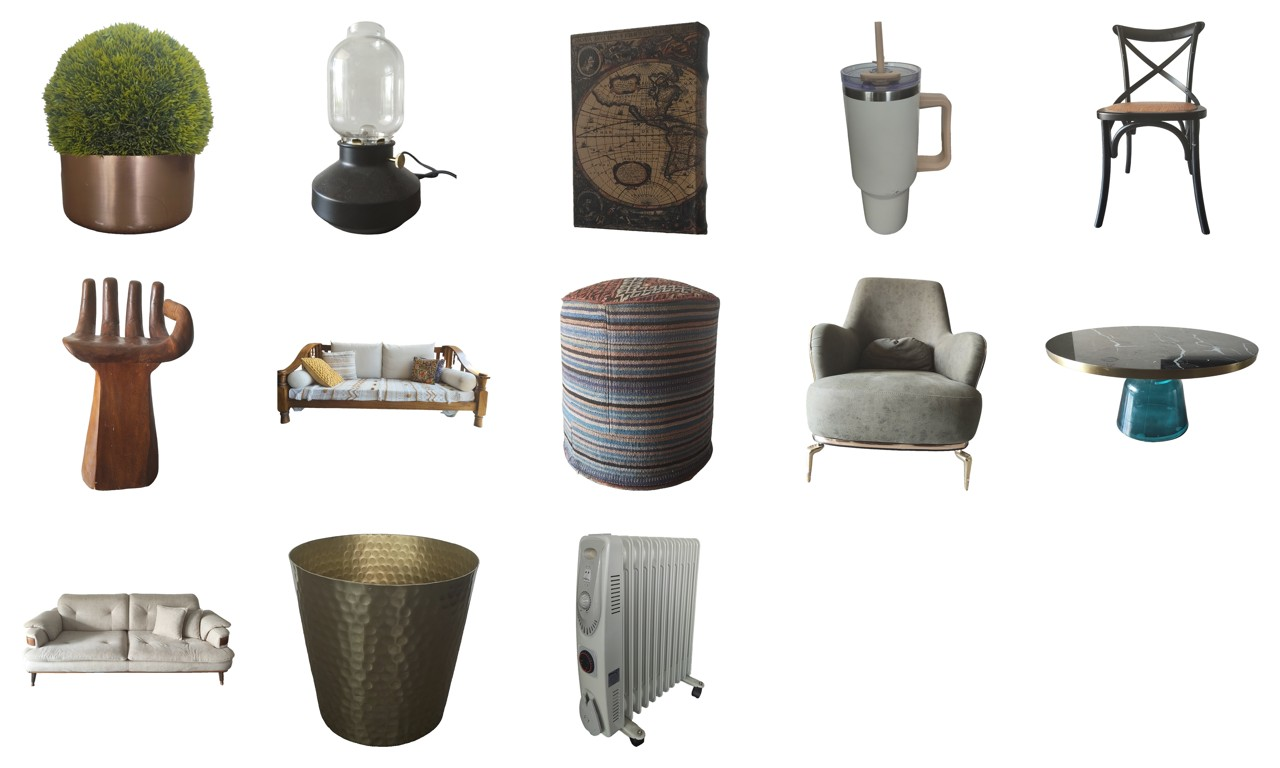

In [12]:
!python pairs/w5_image_to_3d/prepare_inputs.py --raw {BASE}/w5_data/setC
!python pairs/w5_image_to_3d/run_w5.py prep 2>&1 | tail -20
from PIL import Image
display(Image.open('outputs/w5_figures/inputs_sheet.jpg'))

## Cell C: smoke tests (1 item, 1 seed per model). Results go to separate smoke files.
Each model has its own environment, so each runs through `micromamba run`. After both, the last cell scores them and shows the view sheet: check the object stands upright and the textures look right. If a model lies on its side, change `UP_AXIS` in `w5_common.py`.

In [4]:
import os, getpass
os.environ['MAMBA_ROOT_PREFIX'] = '/content/mamba'
os.environ['HF_HOME'] = '/content/hf'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
BASE = '/content/drive/MyDrive/comp8410_a1'
%cd "/content/a1/48576158 Evaluation"
from google.colab import drive
drive.mount('/content/drive')          # a no-op if it is still mounted
from huggingface_hub import login
tok = getpass.getpass('HF token: ')
login(token=tok)
os.environ['HF_TOKEN'] = tok
!ls results outputs | head -3

/content/a1/48576158 Evaluation
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
outputs:
w2
w3


In [9]:
!/content/bin/micromamba run -n trellis2 pip list 2>/dev/null | grep -iE "^(transformers|huggingface|tokenizers|torch|safetensors) "
!grep -n -iE "transformers|huggingface" /content/TRELLIS.2/setup.sh | head
!grep -n -B3 -A12 "self.model.layer\|DINOv3ViTModel\|from_pretrained" /content/TRELLIS.2/trellis2/modules/image_feature_extractor.py | head -70
!cd /content/TRELLIS.2 && /content/bin/micromamba run -n trellis2 python -c "from transformers import DINOv3ViTModel, AutoConfig; c=AutoConfig.from_pretrained('facebook/dinov3-vitl16-pretrain-lvd1689m'); import torch; m=DINOv3ViTModel(c); print('children:', [n for n,_ in m.named_children()]); print('model.layer present:', hasattr(m,'layer'))" 2>&1 | tail -4

safetensors              0.8.0
tokenizers               0.23.3
torch                    2.6.0+cu124
transformers             5.20.2
80:    pip install imageio imageio-ffmpeg tqdm easydict opencv-python-headless ninja trimesh transformers gradio==6.0.1 tensorboard pandas lpips zstandard
2-import torch
3-import torch.nn.functional as F
4-from torchvision import transforms
5:from transformers import DINOv3ViTModel
6-import numpy as np
7-from PIL import Image
8-
9-
10-class DinoV2FeatureExtractor:
11-    """
12-    Feature extractor for DINOv2 models.
13-    """
14-    def __init__(self, model_name: str):
15-        self.model_name = model_name
16-        self.model = torch.hub.load('facebookresearch/dinov2', model_name, pretrained=True)
17-        self.model.eval()
--
62-    """
63-    def __init__(self, model_name: str, image_size=512):
64-        self.model_name = model_name
65:        self.model = DINOv3ViTModel.from_pretrained(model_name)
66-        self.model.eval()
67-        self.i

In [10]:
import subprocess
MT = ['/content/bin/micromamba', 'run', '-n', 'trellis2']
chk = ("import sys, transformers; from transformers import DINOv3ViTModel, AutoConfig; "
       "c = AutoConfig.from_pretrained('facebook/dinov3-vitl16-pretrain-lvd1689m'); m = DINOv3ViTModel(c); "
       "print(transformers.__version__, 'has .layer:', hasattr(m, 'layer')); sys.exit(0 if hasattr(m, 'layer') else 1)")
for v in ['4.57.1', '4.56.2']:
    out = subprocess.run(MT + ['pip', 'install', '-q', f'transformers=={v}'], capture_output=True, text=True)
    r = subprocess.run(MT + ['python', '-c', chk], capture_output=True, text=True)
    print('pin', v, '->', r.stdout.strip() or r.stderr[-300:])
    if r.returncode == 0:
        break
!/content/bin/micromamba run -n trellis2 pip list 2>/dev/null | grep -iE "^(transformers|huggingface-hub|tokenizers) "

pin 4.57.1 -> 4.57.1 has .layer: True
tokenizers               0.22.2
transformers             4.57.1


In [13]:
!git -C /content/a1 pull

Already up to date.


In [11]:
%cd "/content/a1/48576158 Evaluation"
os.environ['PYTHONPATH'] = '/content/TRELLIS.2'
!cd /content/TRELLIS.2 && /content/bin/micromamba run -n trellis2 python "/content/a1/48576158 Evaluation/pairs/w5_image_to_3d/gen_trellis2.py" --items c01_topiary --seeds 0 --out-root /content/smoke_out --results "/content/a1/48576158 Evaluation/results/w5_smoke.jsonl" 2>&1 | tee {BASE}/logs/w5_smoke_trellis2.log | grep -v Warning | tail -40

/content/a1/48576158 Evaluation
    return func(*args, **kwargs)
  File "/content/TRELLIS.2/trellis2/pipelines/samplers/flow_euler.py", line 121, in sample
    out = self.sample_once(model, sample, t, t_prev, cond, **kwargs)
  File "/content/mamba/envs/trellis2/lib/python3.10/site-packages/torch/utils/_contextlib.py", line 116, in decorate_context
    return func(*args, **kwargs)
  File "/content/TRELLIS.2/trellis2/pipelines/samplers/flow_euler.py", line 79, in sample_once
    pred_x_0, pred_eps, pred_v = self._get_model_prediction(model, x_t, t, cond, **kwargs)
  File "/content/TRELLIS.2/trellis2/pipelines/samplers/flow_euler.py", line 49, in _get_model_prediction
    pred_v = self._inference_model(model, x_t, t, cond, **kwargs)
  File "/content/TRELLIS.2/trellis2/pipelines/samplers/guidance_interval_mixin.py", line 11, in _inference_model
    return super()._inference_model(model, x_t, t, cond, guidance_strength=guidance_strength, **kwargs)
  File "/content/TRELLIS.2/trellis2/pipelin

In [14]:
import os
os.environ['MAMBA_ROOT_PREFIX'] = '/content/mamba'
!/content/bin/micromamba run -n hunyuan pip install "setuptools<70" hf_xet 2>&1 | tail -2
!/content/bin/micromamba run -n hunyuan python -c "import pkg_resources, pytorch_lightning; print('PKG_RESOURCES OK')" 2>&1 | tail -2
%cd "/content/a1/48576158 Evaluation"
!git -C /content/a1 pull -q


<string>:1: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
PKG_RESOURCES OK
/content/a1/48576158 Evaluation


In [15]:
!cd /content/Hunyuan3D-2.1 && /content/bin/micromamba run -n hunyuan env MAMBA_ROOT_PREFIX=/content/mamba python "/content/a1/48576158 Evaluation/pairs/w5_image_to_3d/gen_hunyuan3d.py" --items c01_topiary --seeds 0 --out-root /content/smoke_out --results "/content/a1/48576158 Evaluation/results/w5_smoke.jsonl" 2>&1 | tee {BASE}/logs/w5_smoke_hunyuan.log | grep -v Warning | tail -30

2026-10-31 05:14:33,713 - hy3dgen.shapgen - INFO - Try to load model from local path: /root/.cache/hy3dgen/tencent/Hunyuan3D-2.1/hunyuan3d-dit-v2-1
2026-10-31 05:14:33,721 - hy3dgen.shapgen - INFO - Loading model from /root/.cache/hy3dgen/tencent/Hunyuan3D-2.1/hunyuan3d-dit-v2-1/model.fp16.ckpt
Torchvision version: 0.20.1+cu124
torchvision.transforms.functional_tensor not found, applying compatibility fix...
Applied compatibility fix: created functional_tensor mock module
using moe
using moe
using moe
using moe
using moe
using moe
PointCrossAttentionEncoder INFO: pc_sharpedge_size is zero
Loading pipeline components...: 100%|██████████| 6/6 [00:12<00:00,  2.12s/it]
Models Loaded.
[hunyuan3d] loaded in 75s on {'gpu': 'NVIDIA A100-SXM4-40GB', 'gpu_gb': 39.5, 'torch': '2.5.1+cu124'}
Volume Decoding: 100%|██████████| 7134/7134 [00:17<00:00, 408.10it/s]
[hunyuan3d] warm-up call 203s (not recorded)
Volume Decoding: 100%|██████████| 7134/7134 [00:17<00:00, 410.64it/s]
[hunyuan3d] c01_topiary 

In [1]:
!uptime; free -g | head -2; df -h /content | tail -1
!ls /content/mamba/envs /content/smoke_out/hunyuan3d 2>&1 | head
!nvidia-smi --query-gpu=name,memory.used --format=csv
!dmesg 2>/dev/null | grep -i -E "killed process|out of memory" | tail -3

 05:30:51 up  2:58,  0 user,  load average: 0.10, 0.52, 1.01
               total        used        free      shared  buff/cache   available
Mem:              83           2          80           0           1          81
overlay         236G   97G  139G  42% /
/content/mamba/envs:
hunyuan
trellis2

/content/smoke_out/hunyuan3d:
c01_topiary_s0.glb
c01_topiary_s0.json
name, memory.used [MiB]
NVIDIA A100-SXM4-40GB, 0 MiB
[10367.990569] Memory cgroup out of memory: Killed process 186540 (python) total-vm:189247304kB, anon-rss:84429664kB, file-rss:114456kB, shmem-rss:19200kB, UID:0 pgtables:168112kB oom_score_adj:0
[10368.536562] Memory cgroup out of memory: Killed process 104732 (python3) total-vm:1312900kB, anon-rss:122664kB, file-rss:512kB, shmem-rss:0kB, UID:0 pgtables:544kB oom_score_adj:0


In [2]:
%cd "/content/a1/48576158 Evaluation"
!python pairs/w5_image_to_3d/score_w5.py --models hunyuan3d --items c01_topiary --seeds 0 --out-root /content/smoke_out --results results/w5_smoke.jsonl --views-root /content/smoke_views 2>&1 | tail -8
import glob
from PIL import Image
for f in sorted(glob.glob('/content/smoke_views/hunyuan3d/*.jpg')):
    display(Image.open(f))

/content/a1/48576158 Evaluation
Loading weights: 100%|██████████| 223/223 [00:00<00:00, 5831.71it/s]


Loading weights: 100%|██████████| 223/223 [00:00<00:00, 682.96it/s]
hunyuan3d c01_topiary s0: dino 0.732 clip 0.845 iou 0.919 faces 40000
scored 1 meshes
SMOKE FAILED, missing [('trellis2', 'dino_best'), ('trellis2', 'gen_ok'), ('trellis2', 'latency_s'), ('trellis2', 'n_faces'), ('trellis2', 'sil_iou_best')]
/content/smoke_views/hunyuan3d/c01_topiary_s0.jpg


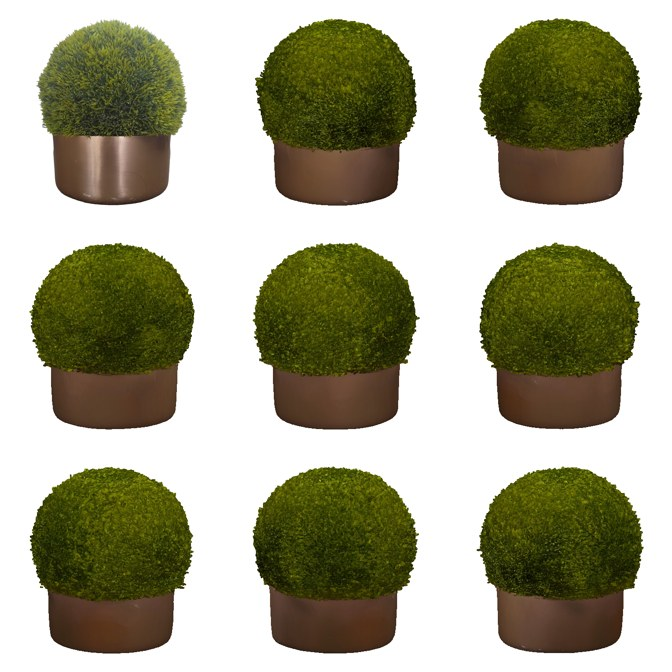

In [8]:
!python pairs/w5_image_to_3d/score_w5.py --items c01_topiary --seeds 0 --out-root /content/smoke_out --results results/w5_smoke.jsonl --views-root /content/smoke_views 2>&1 | tail -10
import glob
from PIL import Image
from a1eval import load
rows = load('results/w5_smoke.jsonl')
need = {(m, k) for m in ('trellis2', 'hunyuan3d') for k in ('gen_ok', 'latency_s', 'dino_best', 'sil_iou_best', 'n_faces')}
got = {(r.model, r.metric) for r in rows if (r.metric != 'gen_ok' or r.value == 1.0)}
print('SMOKE PASSED' if need <= got else f'SMOKE FAILED, missing {sorted(need - got)}')
for f in sorted(glob.glob('/content/smoke_views/*/*.jpg')):
    print(f); display(Image.open(f))

## Cell D: full run (13 items x 3 seeds x 2 models = 78 meshes + 2 warm-ups)
Resumable: finished meshes are skipped, so after an interruption run the same cell again. Meshes go to `outputs/w5/` on Drive. Expect roughly 1-2 hours on the A100; watch the first few lines for per-mesh times and stop if one model is far slower than planned.

In [ ]:
!cd /content/TRELLIS.2 && /content/bin/micromamba run -n trellis2 env MAMBA_ROOT_PREFIX=/content/mamba python "/content/a1/48576158 Evaluation/pairs/w5_image_to_3d/gen_trellis2.py" 2>&1 | tee -a {BASE}/logs/w5_gen_trellis2.log | grep -v Warning | tail -50

In [ ]:
!cd /content/Hunyuan3D-2.1 && /content/bin/micromamba run -n hunyuan env MAMBA_ROOT_PREFIX=/content/mamba python "/content/a1/48576158 Evaluation/pairs/w5_image_to_3d/gen_hunyuan3d.py" 2>&1 | tee -a {BASE}/logs/w5_gen_hunyuan.log | grep -v Warning | tail -50

In [ ]:
!python pairs/w5_image_to_3d/score_w5.py --models trellis2 hunyuan3d --seeds 0 1 2 2>&1 | tee {BASE}/logs/w5_score.log | tail -20

## Cell E: tables, charts, qualitative grid
The grid shows the photographed objects, so keep *Omit code cell output when saving* ticked.

In [ ]:
!python pairs/w5_image_to_3d/report_w5.py --show 2>&1 | tee {BASE}/logs/w5_report.log | grep -v Warning
!mkdir -p {BASE}/report_assets && cp -r report_assets/w5 {BASE}/report_assets/
!/content/bin/micromamba run -n trellis2 pip freeze > {BASE}/results/w5_ENV_trellis2.txt
!/content/bin/micromamba run -n hunyuan pip freeze > {BASE}/results/w5_ENV_hunyuan.txt
!git -C /content/TRELLIS.2 rev-parse HEAD > {BASE}/results/w5_commit_trellis2.txt
!git -C /content/Hunyuan3D-2.1 rev-parse HEAD > {BASE}/results/w5_commit_hunyuan.txt
!cp /content/Hunyuan3D-2.1/LICENSE* {BASE}/results/ 2>/dev/null
from PIL import Image
display(Image.open('outputs/w5_figures/w5_qualitative.jpg'))

## Last cell: free the GPU
Set `AUTO_DISCONNECT = True` once everything has been copied to Drive.

In [ ]:
AUTO_DISCONNECT = True
if AUTO_DISCONNECT:
    from google.colab import runtime
    runtime.unassign()